# SentimentAI Banking · versión 2 · Actividad 5
**Elizabeth Rivera Noguez — Gestión de proyectos de inteligencia artificial**

Evolución de la actividad 4: de sentimiento en comentarios sintéticos en español a **clasificación de intención en consultas bancarias públicas en inglés**. Son tareas y datasets diferentes; sus métricas no se comparan directamente.

Se entrenan regresión logística y Naive Bayes multinomial con TF-IDF. Grid Search de seis configuraciones por algoritmo, validación estratificada de cinco particiones y selección por F1 macro en entrenamiento.

Fuente: [BANKING77 de PolyAI](https://github.com/PolyAI-LDN/task-specific-datasets). Casanueva et al. (2020), *Efficient Intent Detection with Dual Sentence Encoders*. Datos CC BY 4.0; se incluye atribución y licencia.

## 1. Cargar el proyecto

In [ ]:
from pathlib import Path
import io, zipfile
ROOT = Path('/content/Actividad5')
if not (ROOT/'fuentes/train.py').exists():
    from google.colab import files
    print('Selecciona SentimentAI_Banking_v2_Actividad5.zip')
    uploaded = files.upload()
    matches = [name for name in uploaded if name.lower().endswith('.zip')]
    if len(matches) != 1:
        raise ValueError('Selecciona solamente el ZIP del proyecto.')
    with zipfile.ZipFile(io.BytesIO(uploaded[matches[0]])) as z:
        for name in z.namelist():
            if not (Path('/content')/name).resolve().is_relative_to(Path('/content')):
                raise ValueError('Ruta no válida dentro del ZIP.')
        z.extractall('/content')
    del uploaded
if not (ROOT/'fuentes/train.py').exists():
    raise FileNotFoundError('El ZIP debe contener la carpeta Actividad5.')
print('Proyecto listo:', ROOT)

Selecciona SentimentAI_Banking_v2_Actividad5.zip


Saving SentimentAI_Banking_v2_Actividad5 2.zip to SentimentAI_Banking_v2_Actividad5 2.zip
Proyecto listo: /content/Actividad5


## 2. Instalar dependencias


In [ ]:
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'requirements.txt')],check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', '/content/Actividad5/requirements.txt'], returncode=0)

## 3. Preparación y calidad
Se normalizan Unicode, espacios y mayúsculas, preservando negaciones y puntuación. Se auditan vacíos y conflictos de etiqueta. Los duplicados se controlan dentro de cada partición; las coincidencias entre particiones se retiran del entrenamiento para preservar un test independiente. No se inventan nulos ni anomalías.

TF-IDF se ajusta **dentro de cada fold**, evitando que el vocabulario y los pesos del conjunto de validación entren en el aprendizaje. No se aplica escalado numérico adicional: TF-IDF utiliza normalización L2. Las etiquetas categóricas son las 77 intenciones originales.

In [ ]:
subprocess.run([sys.executable,str(ROOT/'fuentes/datos_prep.py')],check=True)
import pandas as pd, json
train=pd.read_csv(ROOT/'datos/datos_limp/train.csv')
test=pd.read_csv(ROOT/'datos/datos_limp/test.csv')
display(train.head())
display(train['category'].value_counts().describe())

,id,text,category,text_original
0,train_00000,i am still waiting on my card?,card_arrival,I am still waiting on my card?
1,train_00001,what can i do if my card still hasn't arrived ...,card_arrival,What can I do if my card still hasn't arrived ...
2,train_00002,i have been waiting over a week. is the card s...,card_arrival,I have been waiting over a week. Is the card s...
3,train_00003,can i track my card while it is in the process...,card_arrival,Can I track my card while it is in the process...
4,train_00004,"how do i know if i will get my card, or if it ...",card_arrival,"How do I know if I will get my card, or if it ..."


,count
count,77.000000
mean,129.766234
std,33.079607
min,35.000000
25%,111.000000
50%,127.000000
75%,159.000000
max,187.000000


## 4. Entrenar, ajustar y registrar en MLflow
- Regresión logística: C = 0.5, 2, 8. Contrasta distinta regularización.
- Naive Bayes multinomial: alpha = 0.1, 0.5, 1. Contrasta suavizado para términos poco frecuentes.
- Ambos: unigramas o unigramas + bigramas; min_df = 2; hasta 30,000 términos.
- Cinco folds idénticos, semilla 42; seis candidatos por algoritmo, 60 ajustes CV más los dos reajustes finales.
- Cada candidato queda registrado como ejecución hija; cada modelo final se guarda y se prueba su recuperación desde MLflow.

Se selecciona por F1 macro de CV. Se informa accuracy, precision, recall, F1 macro y ROC-AUC multiclase OVR macro en test. Los scores no se interpretan como probabilidades calibradas.

In [ ]:
subprocess.run([sys.executable,str(ROOT/'fuentes/train.py')],check=True)

CompletedProcess(args=['/usr/bin/python3', '/content/Actividad5/fuentes/train.py'], returncode=0)

## 5. Resultados y análisis estadístico
El test limpio difiere ligeramente del oficial por la deduplicación documentada. McNemar exacto compara los aciertos pareados; bootstrap estratificado produce un intervalo para la diferencia de accuracy. No se presenta la desviación de los folds como intervalo de confianza ni se usa el test para elegir hiperparámetros.

,modelo,cv_f1_macro,cv_f1_std,busqueda_segundos,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
0,Regresion_logistica,0.882391,0.005681,120.976861,0.900617,0.904932,0.900633,0.900783,0.998050
1,Multinomial_NB,0.839078,0.012154,14.565119,0.856772,0.865434,0.856793,0.855759,0.997335


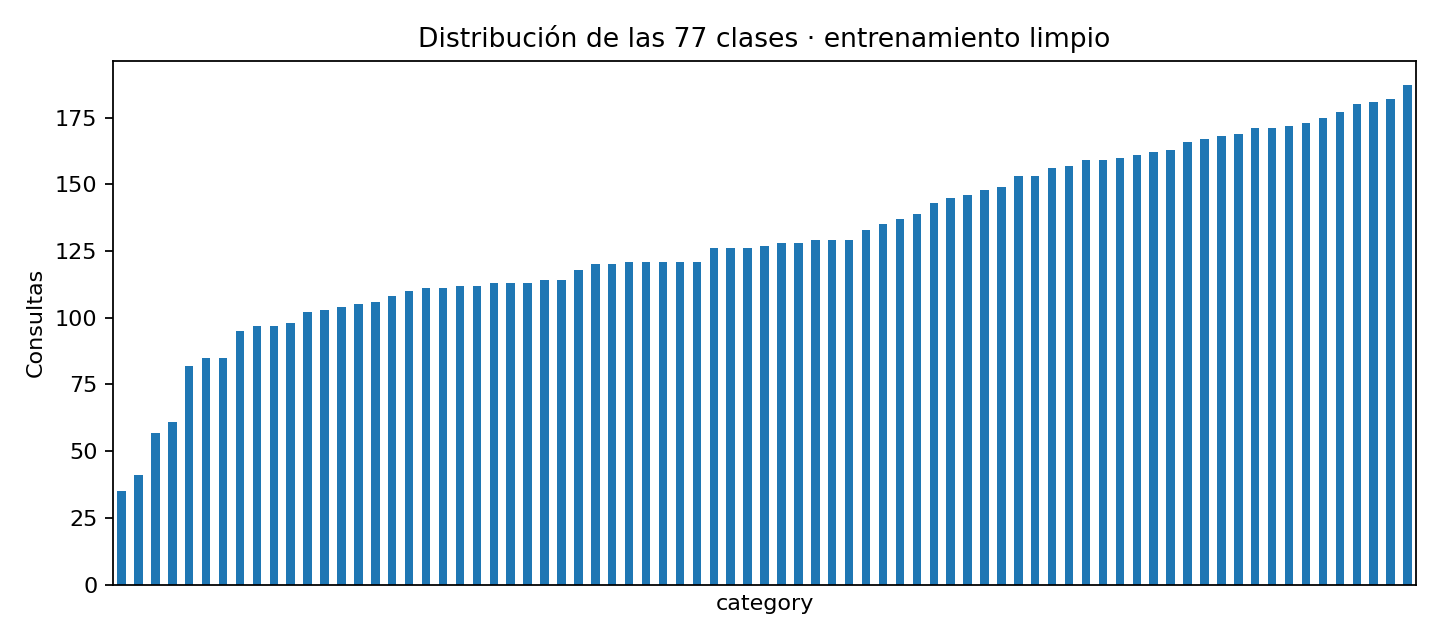

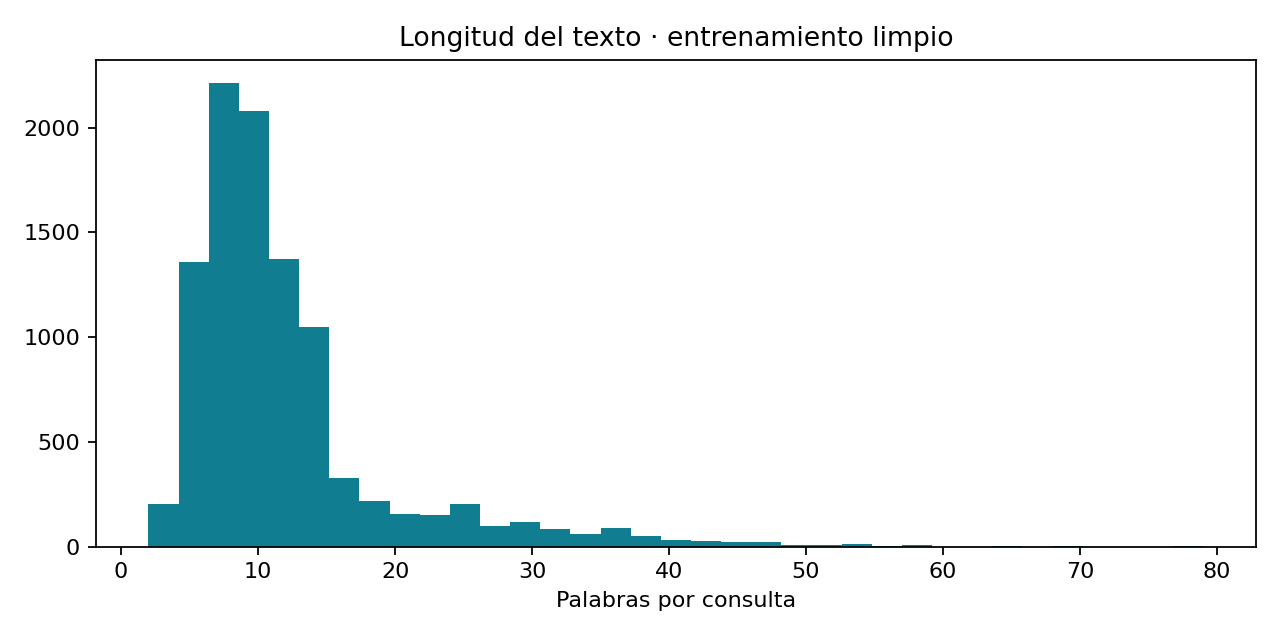

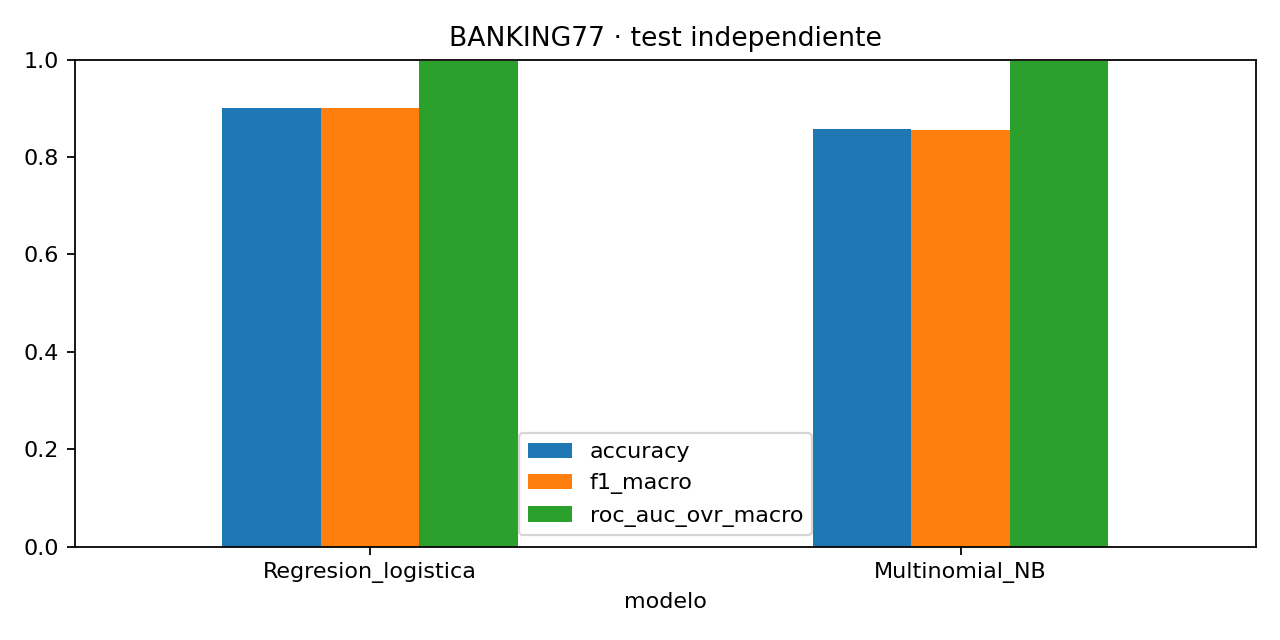

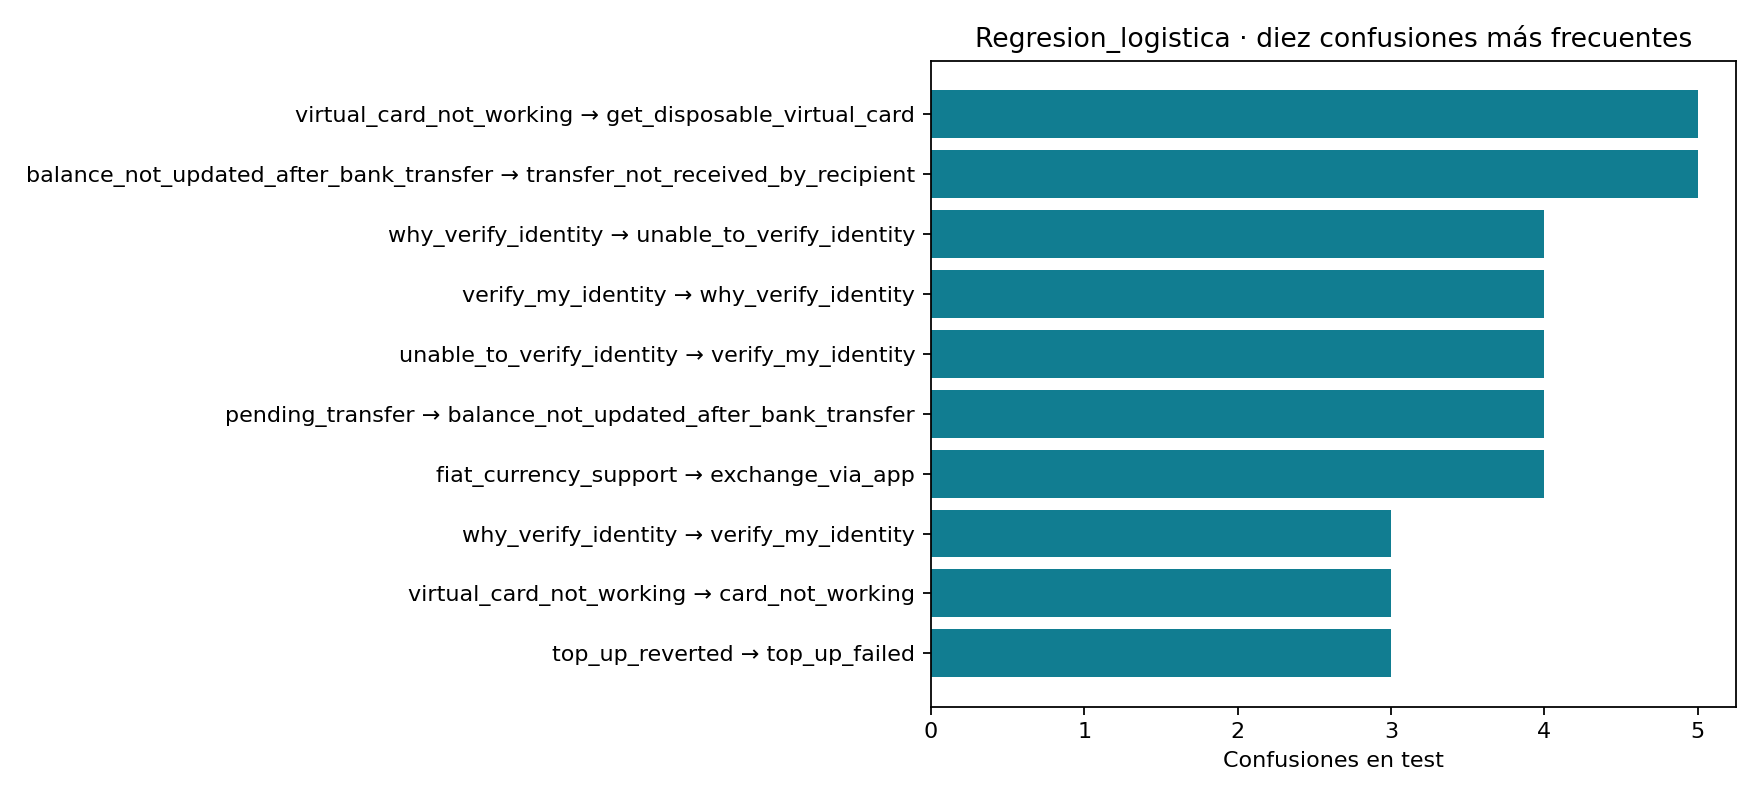

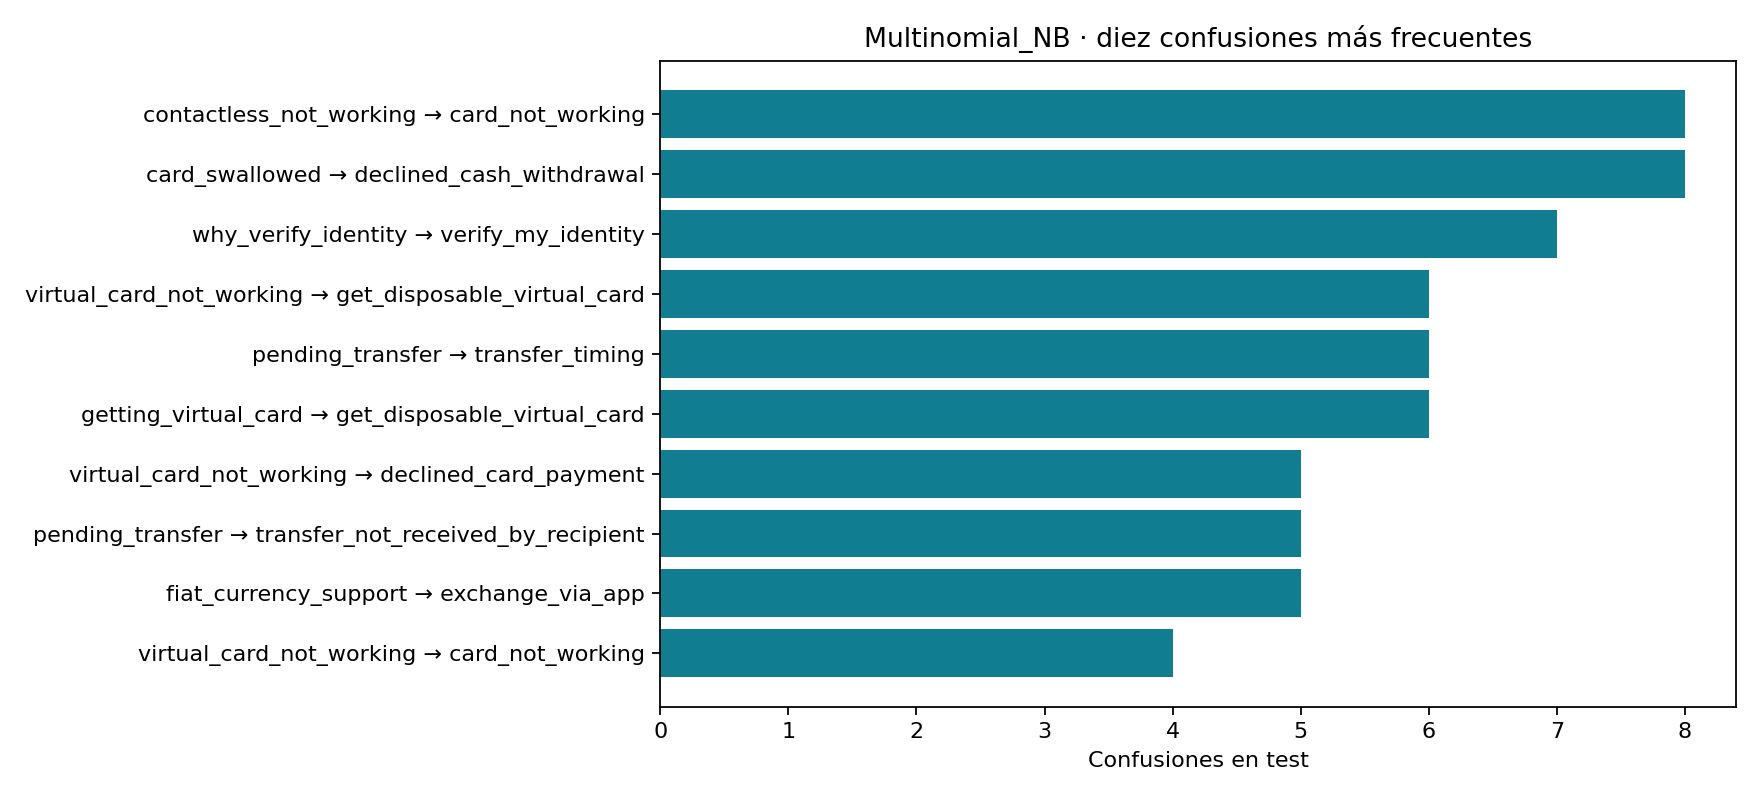

{
  "modelo_A": "Regresion_logistica",
  "modelo_B": "Multinomial_NB",
  "seleccionado_por_CV": "Regresion_logistica",
  "solo_A_acierta": 201,
  "solo_B_acierta": 66,
  "mcnemar_exacto_p": 4.9460565388946843e-17,
  "diferencia_accuracy_A_menos_B": 0.0438454043520623,
  "IC95_bootstrap_pareado_estratificado_accuracy": [
    0.03312763884378045,
    0.054238389087366
  ],
  "bootstrap_replicas": 1000,
  "limite": "Comparaci\u00f3n de aciertos en un test fijo; no demuestra rendimiento en espa\u00f1ol ni en producci\u00f3n. La dispersi\u00f3n CV no es un intervalo de confianza independiente."
}
Baseline: {
  "accuracy": 0.012991230919129588,
  "f1_macro": 0.00033310709809587655,
  "regla": "clase_mayoritaria_train"
}


In [ ]:
from IPython.display import display, Image
metrics=pd.read_csv(ROOT/'resultados/metricas.csv')
display(metrics)
for name in ['distribucion_clases.png','longitud_textos.png','comparacion.png','errores_Regresion_logistica.png','errores_Multinomial_NB.png']:
    display(Image(filename=str(ROOT/'resultados'/name)))
print((ROOT/'resultados/comparacion_estadistica.json').read_text())
print('Baseline:',(ROOT/'resultados/baseline.json').read_text())

## 6. Revisar errores y tomar una decisión
La recomendación se basa en CV. Revisar también categorías confundidas, brecha entre entrenamiento y validación y relevancia del error para el servicio. Un p-value pequeño no demuestra utilidad operativa.

El conjunto está en inglés, no representa por sí mismo a clientes mexicanos ni consultas actuales; no se evalúan consultas fuera de las 77 categorías. No autoriza decisiones jurídicas, crediticias ni automatización de reclamaciones.

In [ ]:
for name in metrics.modelo:
    p=pd.read_csv(ROOT/f'resultados/predicciones_{name}.csv')
    print(name)
    display(p.loc[~p.correcto].sort_values('score_maximo',ascending=False).head(5))

Regresion_logistica


,id,text,category,prediccion,score_maximo,correcto
2710,test_02711,my transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer,0.997375,False
2636,test_02637,how many transactions can i make with a dispos...,get_disposable_virtual_card,disposable_card_limits,0.985121,False
2605,test_02606,i would like a temporary virtual card,get_disposable_virtual_card,getting_virtual_card,0.954998,False
2047,test_02048,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer,0.938123,False
1625,test_01626,"i was double charged, and the second charge is...",pending_card_payment,transaction_charged_twice,0.927037,False


Multinomial_NB


,id,text,category,prediccion,score_maximo,correcto
2636,test_02637,how many transactions can i make with a dispos...,get_disposable_virtual_card,disposable_card_limits,0.963749,False
1625,test_01626,"i was double charged, and the second charge is...",pending_card_payment,transaction_charged_twice,0.903510,False
2762,test_02763,where do i find the exchange rate?,exchange_charge,exchange_rate,0.810058,False
2047,test_02048,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer,0.755079,False
11,test_00011,how long does a card delivery take?,card_arrival,card_delivery_estimate,0.753758,False


## 7. Panel real de MLflow y capturas


In [ ]:
import time
log=open(ROOT/'mlflow_servidor.log','w')
server=subprocess.Popen([sys.executable,'-m','mlflow','ui','--backend-store-uri','sqlite:///'+str(ROOT/'mlflow.db'),'--host','0.0.0.0','--port','5000'],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT)
time.sleep(3)
try:
    from google.colab import output
    output.serve_kernel_port_as_window(5000)
except ImportError:
    print('Abrir http://localhost:5000 en el equipo que ejecuta este notebook')

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [13]:
from google.colab import output
output.serve_kernel_port_as_iframe(5000, height=800)

<IPython.core.display.Javascript object>

## 8. Deuda técnica y próximos pasos MLOps
| Deuda o límite | Acción concreta | Evidencia de cierre |
|---|---|---|
| Idioma y dominio limitados | Validar un conjunto independiente en español con revisión humana | Métricas por categoría y errores documentados |
| Falta de detección fuera de dominio | Definir política de abstención y probar consultas desconocidas | Curva cobertura/error sobre validación separada |
| Scores sin calibración | Calibrar con datos de desarrollo separados, si el uso lo requiere | Curvas de calibración y Brier/log-loss |
| Cambio de consultas | Monitorizar distribución de categorías, vocabulario y rendimiento con etiquetas | Alertas y revisión periódica documentadas |
| Ejecución manual | Automatizar validación de esquema, versiones y prueba de carga | Pipeline que detenga publicaciones si falla |
| Artefactos con rutas locales | Reconstruir MLflow al cambiar de entorno y mantener exportación de runs | Ejecución completa reproducida y modelo recuperado |



## 9. Descargar un resguardo de la ejecución


In [15]:
import shutil
zip_path=shutil.make_archive(str(ROOT.parent/'Actividad5_ejecutada'),'zip',ROOT.parent,ROOT.name)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>